---
---

<h1><center><ins>Numerical Methods: Exam 1</ins></center></h1>
<h2><center>November 11, 09:45-11:15 </center></h2>

Please answer the short questions related to the numerical methods we discussed during the lectures. Provide short and concise (one-two sentences) answers.

Solve the two exercises in the python notebook, *documenting your code* where needed, or create .py files that are documented.

Remember to answer any discussion points asked in the question to obtain maximum points.  

***Before 11:20*** your files need to be uploaded to GitHub.<br>
<br>
This means you have roughly 90 minutes to complete the exercises and answer the questions.

You may use the lecture notes and any of your exercises freely, but you can **not** use ChatGPT code assistant or other AI coding tools such as Claude.<br> 
**_Collaboration or plagarized code except your own is prohibited and no phones or communication will be allowed_**.

---
---

## Short questions
1. Name the root-finding methods we have discussed during the lectures, and rank them by their precision. Do all methods always converge? (**2 points**)
2. What is the difference between the trapezoid rule and the Simpson's rule in the Newton-Cotes numerical integration? (**2 points**)
3. What is the simplest way of expanding 1D interpolation methods to 2D? (**2 points**) 
4. What is LU decomposition and why is it used when solving sets of linear algebraic equations? (**2 points**)
5. What is the Jacobian matrix in the Newton-Raphson Method for nonlinear systems of equations? Can the Newton-Raphson method always find a solution for a nonlinear system of equations? (**2 points**)

1.
Highest to lowest precision:
- Newton-Raphson
- Secant Method
- False Position
- Bisection Method

Only Bisection and False Position always converge.


2.
In the trapezoid rule you construct linear functions while in the Simpson's rule you construct polynomials of order >= 2 between eatch abscissa to calculate the integral.

3.
Bilinear interpolation. First you interpolate linearly in x-direction, then you interpolate the resulting values linearly in the y-direction (or the other way around).

4.
In LU decomposition you decompose a given matrix A into a lower and upper component. Each of these only have components either below or above the diagonal (but they also have diagonal values). This way you get L @ U @ x = b. To solve for x you first solve for L @ y = b, where y = U @ x and then you solve for U @ x = y. The trick is that the shape of L and U makes it trivial to solve the equation.

5.
The Jacobian matrix is the equivalent to the derivative of a function in one dimension. We can approximate F(x + dx) ~ F(x) + J @ dx.
Setting F(x + dx) = 0 we get dx = J^-1 @ F(x) which should lead us closer to the root. However this method doesn't always converge, expecially if the initial guess is poor, if det(J) = 0 or if a root doesn't exist.


## Exercise 1. Interpolating the luminosity profile of a galaxy (10 Points)

Imagine an elliptical galaxy with the light intensity profile described by the de Vaucouleurs's law. We have observed four datapoints for the intensity in units of $L_\odot/pc^2$ at the corresponding radii in pc:

\begin{aligned}
(R_0,I_0) &= (0,\;2.14\times10^5),\\
(R_1,I_1) &= (1000,\;1.14\times10^3),\\
(R_2,I_2) &= (1500,\;5.51\times10^2),\\
(R_3,I_3) &= (2000,\;3.36\times10^2).
\end{aligned}


Use the Lagrange polynomial interpolation to fit a polynomial to these datapoints.

**(a)** What is the highest polynomial degree that you can fit to the four datapoints? (**1 point**)

**(b)** Interpolate the datapoints using your polynomial (**5 points** if you use your own Lagrange polynomial, **1 point** if you use embedded python fucntions).

**(c)** Use embedded functions for numerical integration such as **quad** or **simpson** to integrate your Lagrange polynomial that represents your luminosity profile from zero to 2000 pc to obtain the approximate luminosity of the galaxy in $L_\odot$. Use the print command to show the result (**2 points**)

**(d)** Plot your results: the four datapoints and the polynomial that you used to interpolate the function (**2 points**)



The highest polynomial fit is of order 3 since we have 4 datapoints.

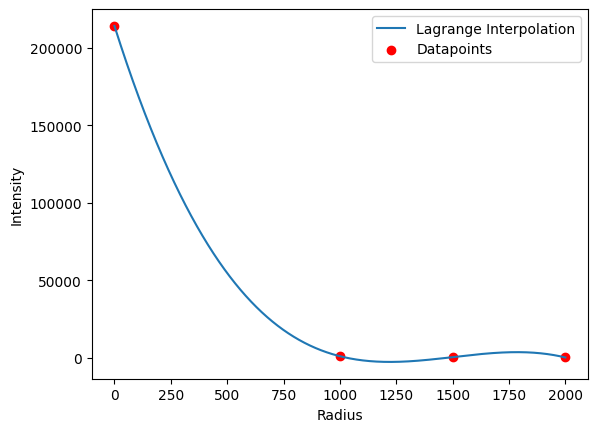

In [35]:
import numpy as np
import matplotlib.pyplot as plt

def lagrange_pol(x):
    x_i = np.array([0, 1000, 1500, 2000])
    f_i = np.array([2.14e5, 1.14e3, 5.51e2, 3.36e2])
    # Initialize an array of ones for the Lagrange basis polynomials
    l_i = np.ones((len(x_i), len(x)))

    # Calculate each Lagrange basis polynomial L_i(x)
    for i in range(len(x_i)):
        for j in range(len(x_i)):
            # Skip the term where i = j to avoid division by zero
            if i != j:
                # Multiply by (x - x_j) / (x_i - x_j)
                l_i[i] *= ((x - x_i[j]) / (x_i[i] - x_i[j]))

    # Multiply each basis polynomial by its corresponding function value
    # and sum them to obtain the interpolating polynomial
    return np.sum(l_i * f_i[:, None], axis=0)

r_points = np.array([0, 1000, 1500, 2000])
I_points = np.array([2.14e5, 1.14e3, 5.51e2, 3.36e2])

r = np.linspace(np.min(r_points), np.max(r_points), 10000)
I = lagrange_pol(r)

plt.plot(r, I, label='Lagrange Interpolation')
plt.scatter(r_points, I_points, color='red', label='Datapoints')
plt.legend()
plt.ylabel('Intensity')
plt.xlabel('Radius')
plt.show()



1


In [36]:
from scipy.integrate import quad, simpson

def lagrange_pol(x):
    x = np.array([x])
    x_i = np.array([0, 1000, 1500, 2000])
    f_i = np.array([2.14e5, 1.14e3, 5.51e2, 3.36e2])
    # Initialize an array of ones for the Lagrange basis polynomials
    l_i = np.ones((len(x_i), len(x)))

    # Calculate each Lagrange basis polynomial L_i(x)
    for i in range(len(x_i)):
        for j in range(len(x_i)):
            # Skip the term where i = j to avoid division by zero
            if i != j:
                # Multiply by (x - x_j) / (x_i - x_j)
                l_i[i] *= ((x - x_i[j]) / (x_i[i] - x_i[j]))

    # Multiply each basis polynomial by its corresponding function value
    # and sum them to obtain the interpolating polynomial
    return np.sum(l_i * f_i[:, None], axis=0)

integral_quad, err = quad(lagrange_pol, np.min(r_points), np.max(r_points))
integral_simpson = simpson(I, r)

print('Quad Integral:')
print(integral_quad)
print('Simpson Integral:')
print(integral_simpson)

Quad Integral:
72965333.33333333
Simpson Integral:
72965333.33333328


## Exercise 2. Decelerating satellite and numerical derivation (10 Points)

A small spacecraft is decelerating. It's time-dependent coordinate is given by the following equation (the time is in seconds and the distance is in meters):

$$x(t) = 100 - 50 \exp (-0.2t)$$

**(a)** Determine the spacecraft's speed at $t=5$ s using the forward and central finite-difference methods (the non-symmetrical and symmetrical methods of calculating the numerical derivative) for the $dt = 1$ s (**2 points**)

**(b)** Investigate the accuracy of both methods for different step sizes. Create an array of step sizes ranging from 0.1 s to 2 s and calculate the derivatives for each $dt$ (**2 points**). Compare to the precise analytical formula for speed at $t=5$ s (**2 points**)

**(c)** Plot your results from **(b)** (**2 points**)

**(d)** Which method is more accurate, the central method or the forward method? (**1 point**). Why is one method more accurate than the other from the mathematical point of view (one sentence explanation is enough; **1 point**)



In [25]:
def function(t):
    return 100 - 50 * np.exp(-0.2 * t)

def diff_ana(x):
    return 10 * np.exp(-0.2 * x)

def diff_forward(x, f, h):
    return (f(x + h) - f(x)) / h

def diff_central(x, f, h):
    return (f(x + h) - f(x - h)) / (2 * h)

d_at_5_f = diff_forward(5, function, 1)
d_at_5_c = diff_central(5, function, 1)

print("Forward Finite-Difference:")
print(d_at_5_f)
print("Central Finite-Difference:")
print(d_at_5_c)


Forward Finite-Difference:
3.3342614629620186
Central Finite-Difference:
3.7033688051254856


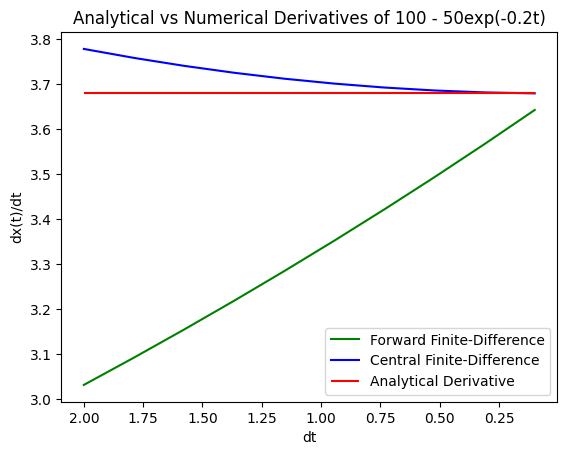

In [38]:
dt = np.linspace(0.1, 2, 10)

dy_f = diff_forward(5, function, dt)
dy_c = diff_central(5, function, dt)
dy_a = diff_ana(5)

plt.title('Analytical vs Numerical Derivatives of 100 - 50exp(-0.2t)')
plt.plot(dt, dy_f, label='Forward Finite-Difference', color='green')
plt.plot(dt, dy_c, label='Central Finite-Difference', color='blue')
plt.hlines(dy_a, xmin=0.1, xmax=2, label='Analytical Derivative', color='red')
plt.xlabel('dt')
plt.ylabel('dx(t)/dt')
plt.gca().invert_xaxis()
plt.legend()
plt.show()

From the plots we can see that the Central Finite-Difference is more accurate. This is because for Central Finite-Difference we enclose the x value symmetrically while for Forward Finite-Difference x is an edge-value.